## i-94 Traffic Dataset Analysis

This project is about the traffic patterns in the i-94. In this project I hope to analyze these trends using explaratory data visualizations to learn more about the data.

Specifically, this data is contained within Saint Paul and Minnesota and measures the westward traffic between the two.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
traffic = pd.read_csv('Metro_Interstate_Traffic_Volume.csv')

In [3]:
traffic

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918
...,...,...,...,...,...,...,...,...,...
48199,NaN,283.45,0.0,0.0,75,Clouds,broken clouds,2018-09-30 19:00:00,3543
48200,NaN,282.76,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 20:00:00,2781
48201,NaN,282.73,0.0,0.0,90,Thunderstorm,proximity thunderstorm,2018-09-30 21:00:00,2159
48202,NaN,282.09,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 22:00:00,1450


In [4]:
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


The `holiday` column is mostly null, rest of the coulumns don't have any null values. The dataset also seems to have the proper data type other thant he `date_time`. 

<Axes: ylabel='Frequency'>

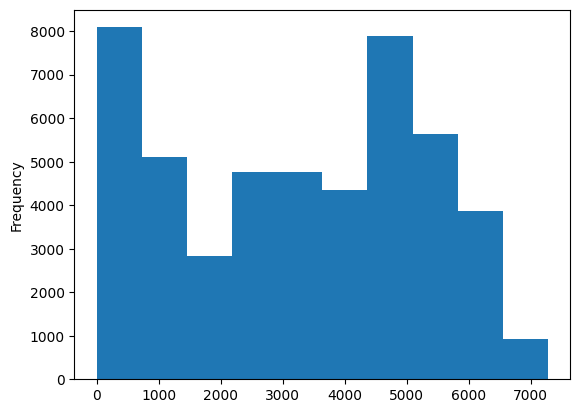

In [5]:
%matplotlib inline

traffic['traffic_volume'].plot.hist()

In [6]:
traffic['traffic_volume'].describe()

count    48204.000000
mean      3259.818355
std       1986.860670
min          0.000000
25%       1193.000000
50%       3380.000000
75%       4933.000000
max       7280.000000
Name: traffic_volume, dtype: float64

The `traffic_volume` dataset seems to be bimodal. The range of the data is between 0 and ~7000. The data peaks between (0, 1000) and also between (5000, 6000). 

The average value in the dataset is 3259, but it does not describe either peak meaning it's not explanatory of the typical value. The standard deviation is also 1986 meaning that the data is pretty scattered.

The IQR of about 3,800 is much larger than we’d expect for a normal distribution with this standard deviation, confirming the data is spread toward both extremes. This suggests that daytime and nighttime influence the traffic volume. 

In [7]:
traffic['date_time'] = pd.to_datetime(traffic['date_time'])

In [8]:
traffic['date_time'].dt.hour

0         9
1        10
2        11
3        12
4        13
         ..
48199    19
48200    20
48201    21
48202    22
48203    23
Name: date_time, Length: 48204, dtype: int32

In [9]:
is_day = traffic['date_time'].dt.hour.between(7, 19, inclusive='left')

daytime_data = traffic[is_day].copy()
nighttime_data = traffic[~is_day].copy()

In [10]:
daytime_data['date_time'].dt.hour.value_counts().sort_index()

date_time
7     2079
8     2080
9     2018
10    2078
11    1952
12    1955
13    1905
14    1969
15    1934
16    1988
17    1933
18    1986
Name: count, dtype: int64

In [11]:
nighttime_data['date_time'].dt.hour.value_counts().sort_index()

date_time
0     2037
1     2049
2     2019
3     2025
4     2091
5     2063
6     2087
19    1961
20    1979
21    1982
22    1994
23    2040
Name: count, dtype: int64

<Axes: ylabel='Frequency'>

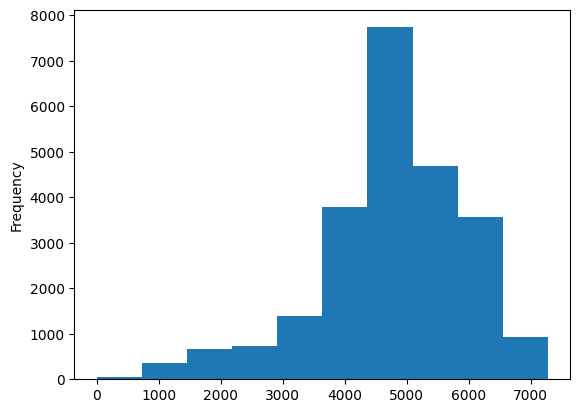

In [12]:
daytime_data['traffic_volume'].plot.hist()

<Axes: ylabel='Frequency'>

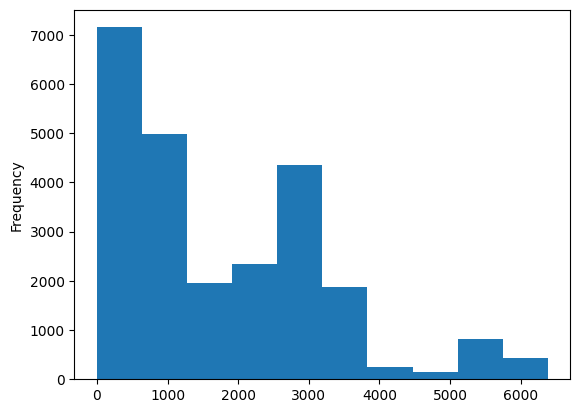

In [13]:
nighttime_data['traffic_volume'].plot.hist()

In [14]:
daytime_data['traffic_volume'].describe()

count    23877.000000
mean      4762.047452
std       1174.546482
min          0.000000
25%       4252.000000
50%       4820.000000
75%       5559.000000
max       7280.000000
Name: traffic_volume, dtype: float64

In [15]:
nighttime_data['traffic_volume'].describe()

count    24327.000000
mean      1785.377441
std       1441.951197
min          0.000000
25%        530.000000
50%       1287.000000
75%       2819.000000
max       6386.000000
Name: traffic_volume, dtype: float64

Both datasets are unimodal and hadescribea tail, although the nighttime has a stronger tail. 

daytime is left-skewed and nighttime is right-skewed. This indicates that the traffic volume is higher during daytime and does down during the night. 

In [16]:
daytime_data.loc[:, 'month'] = daytime_data['date_time'].dt.month
day_by_month = daytime_data.groupby('month').mean(numeric_only=True)

nighttime_data.loc[:, 'month'] = nighttime_data['date_time'].dt.month
night_by_month = nighttime_data.groupby('month').mean(numeric_only=True)

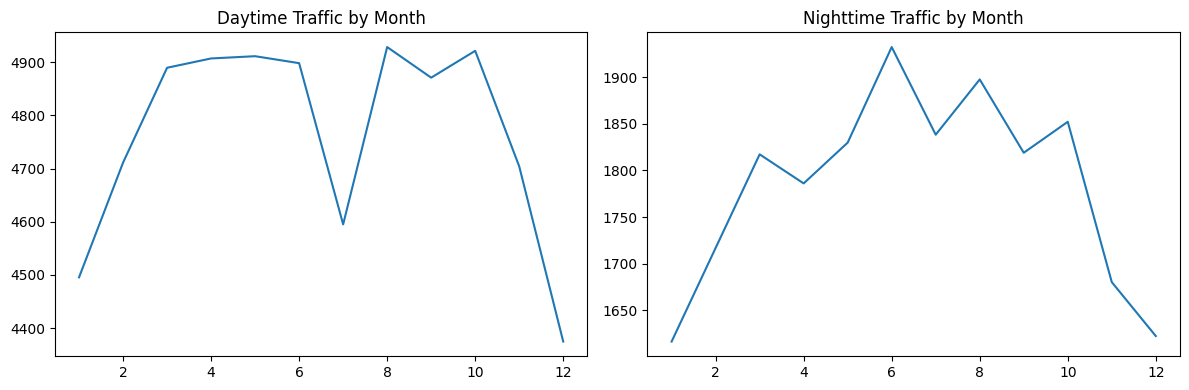

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(day_by_month['traffic_volume'])
plt.title("Daytime Traffic by Month")

plt.subplot(1, 2, 2)
plt.plot(night_by_month['traffic_volume'])
plt.title("Nighttime Traffic by Month")

plt.tight_layout()
plt.show()

In the daytime traffic changes during the months of June through august and then again steeply in November. It seems taht from November-Jan the trafic is low. 

Nighttime follows the Nov-Jan parretn but it does not change as much in the months of june to august. 

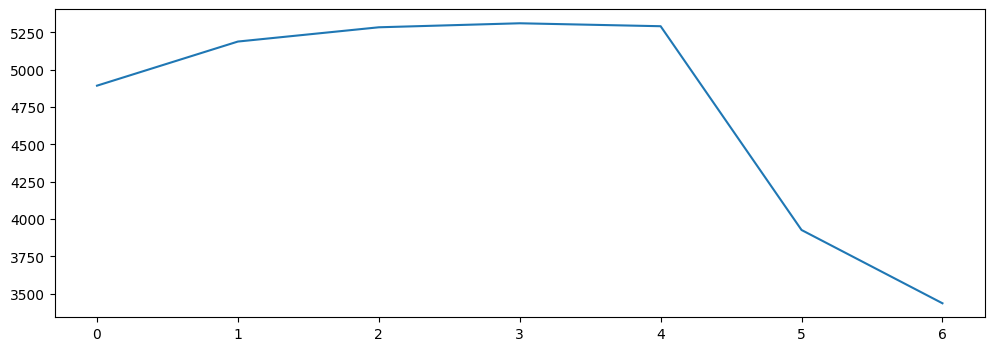

In [18]:
daytime_data['dayofweek'] = daytime_data['date_time'].dt.dayofweek
by_dayofweek = daytime_data.groupby('dayofweek').mean(numeric_only=True)

plt.figure(figsize=(12, 4))
plt.plot(by_dayofweek['traffic_volume'])

Traffic is steady throughout the weekdays and declines steeply during the weekend. This suggests that it is manily made up of people going to/from work.

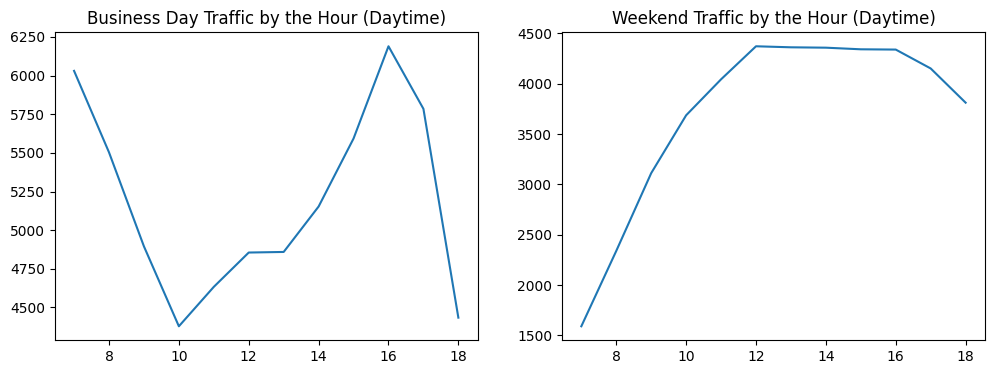

In [23]:
daytime_data['hour'] = daytime_data['date_time'].dt.hour

business_days = daytime_data.copy()[daytime_data['date_time'].dt.dayofweek < 5]
weekends = daytime_data.copy()[daytime_data['date_time'].dt.dayofweek >= 5]

business_days_hours = business_days.groupby('hour').mean(numeric_only=True)
weekend_hours = weekends.groupby('hour').mean(numeric_only=True)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(business_days_hours['traffic_volume'], label="BD")
plt.title("Business Day Traffic by the Hour (Daytime)")

plt.subplot(1, 2, 2)
plt.plot(weekend_hours['traffic_volume'], label="WKND")
plt.title("Weekend Traffic by the Hour (Daytime)")

plt.show()

Weekday rush to and from work also in the afternoon maybe lunch time.

Weekend the traffic is consistent throughout the day although lower than the lowest of the weekday. Suggests people are out and about throughout the day rather than just at specific time periods.

In [24]:
traffic[['traffic_volume', 'temp', 'rain_1h', 'snow_1h']].corr()

,traffic_volume,temp,rain_1h,snow_1h
traffic_volume,1.000000,0.130299,0.004714,0.000733
temp,0.130299,1.000000,0.009069,-0.019755
rain_1h,0.004714,0.009069,1.000000,-0.000090
snow_1h,0.000733,-0.019755,-0.000090,1.000000


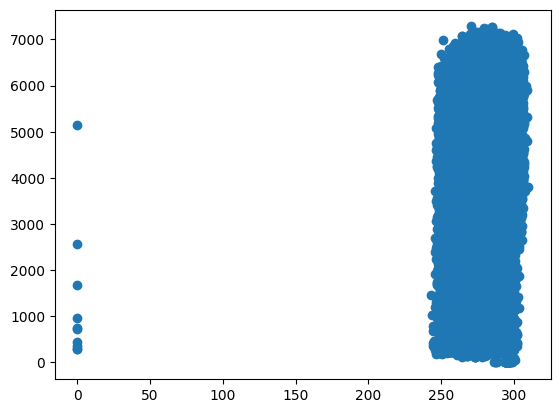

In [27]:
plt.scatter(traffic['temp'], traffic['traffic_volume'])

None of the weather columns seem to be descriptive of the traffic volume. 

In [29]:
by_weather_main = daytime_data.groupby('weather_main').mean(numeric_only=True)
by_weather_description = daytime_data.groupby('weather_description').mean(numeric_only=True)

<Axes: ylabel='weather_main'>

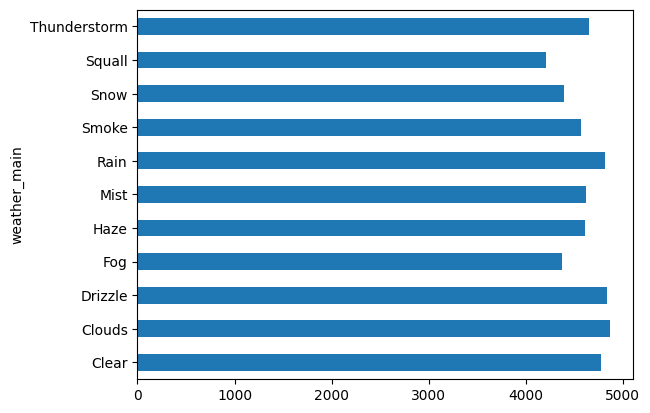

In [31]:
by_weather_main['traffic_volume'].plot.barh()

No matter the weather the traffic seemes to be the same. 

<Axes: ylabel='weather_description'>

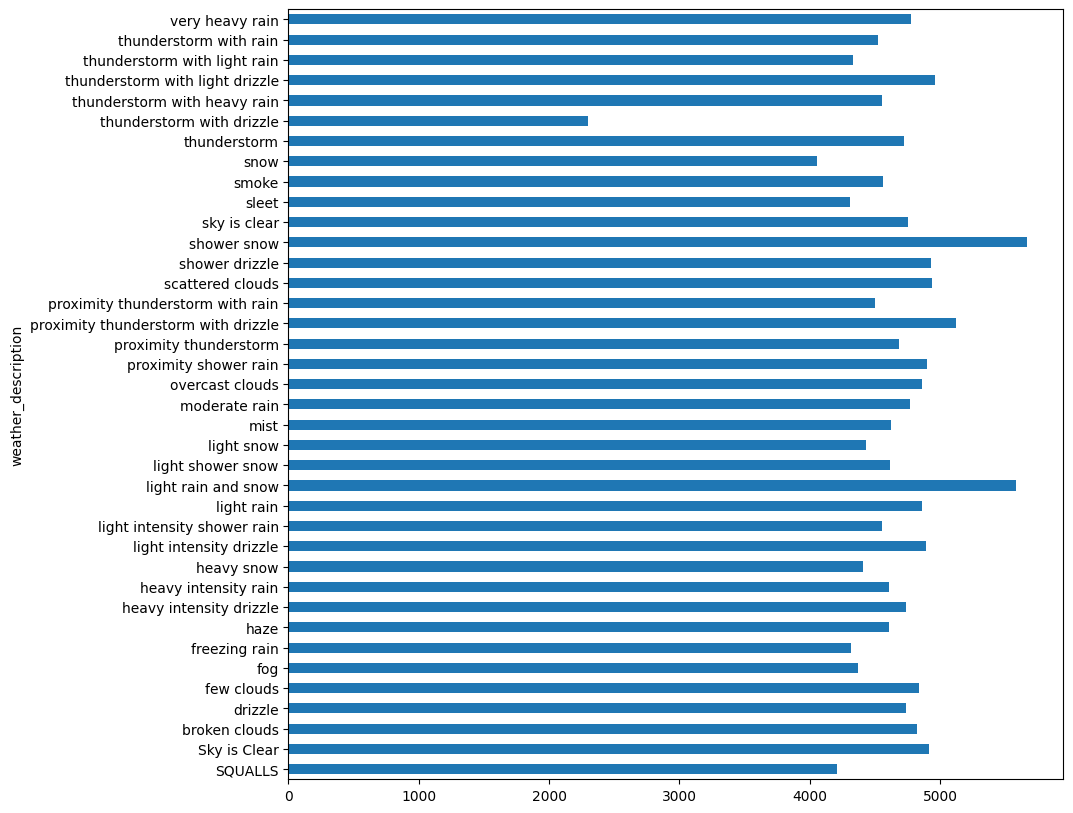

In [33]:
by_weather_description['traffic_volume'].plot.barh(figsize=(10,10))

With more descriptive weather we can see more of a variance with the amount of traffic. Some weather events cross 5000, others are more than half.

Time is the strongest driver of traffic on this stretch of westbound I-94. Daytime traffic (7am to 7pm) is much heavier than nighttime traffic. On weekdays, traffic peaks sharply during the morning and evening rush hours, while on weekends it builds gradually to a lower, broader midday peak. For drivers, this means the best way to avoid congestion is to avoid weekday rush hours.

Weather had little effect on traffic in the broad categories. Some specific weather descriptions, such as thunderstorms, showed noticeably different traffic levels, but these categories contain few observations, so the differences may reflect chance or the time of day those conditions occur rather than the weather itself.